# Phase 2: Anscombe's Quartet Statistical Validation
**Objective:** Calculate mean, variance, Pearson correlation, and least-squares regression for the four Anscombe datasets to prove they share identical summary statistics despite differing spatial geometries.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv('../Data/Cleaned_Data/anscombe_clean.csv')
df

,dataset,x,y
0,I,10.0,8.04
1,I,8.0,6.95
2,I,13.0,7.58
3,I,9.0,8.81
4,I,11.0,8.33
5,I,14.0,9.96
6,I,6.0,7.24
7,I,4.0,4.26
8,I,12.0,10.84
9,I,7.0,4.82


### Computing mean, variance, Pearson correlation and the least-squares line

In [3]:
def compute_mean(arr: np.ndarray) -> float:
    return np.sum(arr) / len(arr)


def compute_sample_variance(arr: np.ndarray, mean_val: float) -> float:
    return np.sum((arr - mean_val) ** 2) / (len(arr) - 1)


def compute_correlation(
    x: np.ndarray, y: np.ndarray, mean_x: float, mean_y: float
) -> float:
    numerator = np.sum((x - mean_x) * (y - mean_y))
    denominator = np.sqrt(np.sum((x - mean_x) ** 2) * np.sum((y - mean_y) ** 2) )
    return numerator/denominator


def compute_linear_regression(
    x: np.ndarray, y: np.ndarray, mean_x: float, mean_y: float
) -> tuple[float, float]:
    beta_1 = np.sum((x - mean_x) * (y - mean_y)) / np.sum((x - mean_x) ** 2)
    beta_0 = mean_y - (beta_1 * mean_x)
    return beta_0, beta_1

### 1. Analysis of Anscombe Dataset I

In [4]:
df1 = df[df['dataset'] == 'I']
df1

,dataset,x,y
0,I,10.0,8.04
1,I,8.0,6.95
2,I,13.0,7.58
3,I,9.0,8.81
4,I,11.0,8.33
5,I,14.0,9.96
6,I,6.0,7.24
7,I,4.0,4.26
8,I,12.0,10.84
9,I,7.0,4.82


In [5]:
df1_mean_x = compute_mean(df1['x'])
df1_mean_y = compute_mean(df1['y'])
print(f"Mean x: {df1_mean_x} | Mean y: {df1_mean_y}")

Mean x: 9.0 | Mean y: 7.500909090909093


In [6]:
df1_var_x = compute_sample_variance(df1['x'], df1_mean_x)
df1_var_y = compute_sample_variance(df1['y'], df1_mean_y)
print(f"Var x: {df1_var_x} | Var y: {df1_var_y}")

Var x: 11.0 | Var y: 4.127269090909091


In [7]:
df1_pearson_xy = compute_correlation(df1["x"],df1['y'],df1_mean_x,df1_mean_y)
print(f"Pearson r: {df1_pearson_xy}")

Pearson r: 0.81642051634484


In [8]:
df1_slope = compute_linear_regression(df1["x"],df1['y'],df1_mean_x,df1_mean_y)
print(f"Slope: {df1_slope}")

Slope: (3.0000909090909103, 0.5000909090909091)


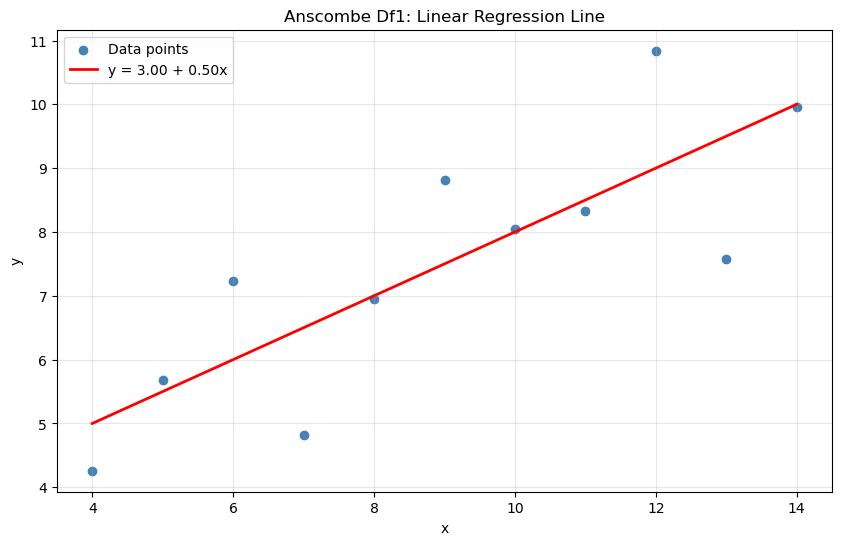

In [9]:
x_line = np.linspace(df1["x"].min(), df1["x"].max(), 100)
y_line = df1_slope[0] + df1_slope[1] * x_line

plt.figure(figsize=(10,6))
plt.scatter(df1["x"], df1["y"], color="steelblue", label="Data points")
plt.plot(x_line, y_line, color="red",
          linewidth=2, label=f"y = {df1_slope[0]:.2f} + {df1_slope[1]:.2f}x")
plt.xlabel("x")
plt.ylabel("y")
plt.title("Anscombe Df1: Linear Regression Line")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### 2. Analysis of Anscombe Dataset II

In [10]:
df2 = df[df['dataset'] == "II"]
df2

,dataset,x,y
11,II,10.0,9.14
12,II,8.0,8.14
13,II,13.0,8.74
14,II,9.0,8.77
15,II,11.0,9.26
16,II,14.0,8.10
17,II,6.0,6.13
18,II,4.0,3.10
19,II,12.0,9.13
20,II,7.0,7.26


In [11]:
df2_mean_x = compute_mean(df2['x'])
df2_mean_y = compute_mean(df2['y'])
print(f"Mean x: {df2_mean_x} | Mean y: {df2_mean_y}")

Mean x: 9.0 | Mean y: 7.50090909090909


In [12]:
df2_var_x = compute_sample_variance(df2['x'], df2_mean_x)
df2_var_y = compute_sample_variance(df2['y'], df2_mean_y)
print(f"Var x: {df2_var_x} | Var y: {df2_var_y}")

Var x: 11.0 | Var y: 4.127629090909091


In [13]:
df2_pearson_xy = compute_correlation(df2["x"],df2['y'],df2_mean_x,df2_mean_y)
print(f"Pearson r: {df2_pearson_xy}")

Pearson r: 0.8162365060002427


In [14]:
df2_slope = compute_linear_regression(df2["x"],df2['y'],df2_mean_x,df2_mean_y)
print(f"Slope: {df2_slope}")

Slope: (3.000909090909091, 0.49999999999999994)


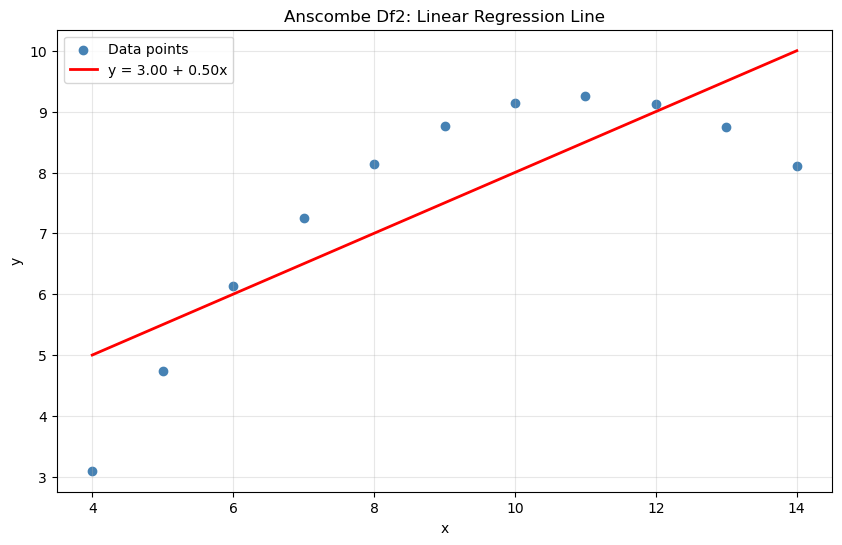

In [15]:
x_line = np.linspace(df2["x"].min(), df2["x"].max(), 100)
y_line = df2_slope[0] + df2_slope[1] * x_line

plt.figure(figsize=(10,6))
plt.scatter(df2["x"], df2["y"], color="steelblue", label="Data points")
plt.plot(x_line, y_line, color="red",
          linewidth=2, label=f"y = {df2_slope[0]:.2f} + {df2_slope[1]:.2f}x")
plt.xlabel("x")
plt.ylabel("y")
plt.title("Anscombe Df2: Linear Regression Line")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### 3. Analysis of Anscombe Dataset III

In [16]:
df3 = df[df['dataset'] == "III"]
df3

,dataset,x,y
22,III,10.0,7.46
23,III,8.0,6.77
24,III,13.0,12.74
25,III,9.0,7.11
26,III,11.0,7.81
27,III,14.0,8.84
28,III,6.0,6.08
29,III,4.0,5.39
30,III,12.0,8.15
31,III,7.0,6.42


In [17]:
df3_mean_x = compute_mean(df3['x'])
df3_mean_y = compute_mean(df3['y'])
print(f"Mean x: {df3_mean_x} | Mean y: {df3_mean_y}")

Mean x: 9.0 | Mean y: 7.5


In [18]:
df3_var_x = compute_sample_variance(df3['x'], df3_mean_x)
df3_var_y = compute_sample_variance(df3['y'], df3_mean_y)
print(f"Var x: {df3_var_x} | Var y: {df3_var_y}")

Var x: 11.0 | Var y: 4.12262


In [19]:
df3_pearson_xy = compute_correlation(df3["x"],df3['y'],df3_mean_x,df3_mean_y)
print(f"Pearson r: {df3_pearson_xy}")

Pearson r: 0.8162867394895981


In [20]:
df3_slope = compute_linear_regression(df3["x"],df3['y'],df3_mean_x,df3_mean_y)
print(f"Slope: {df3_slope}")

Slope: (3.0024545454545457, 0.49972727272727274)


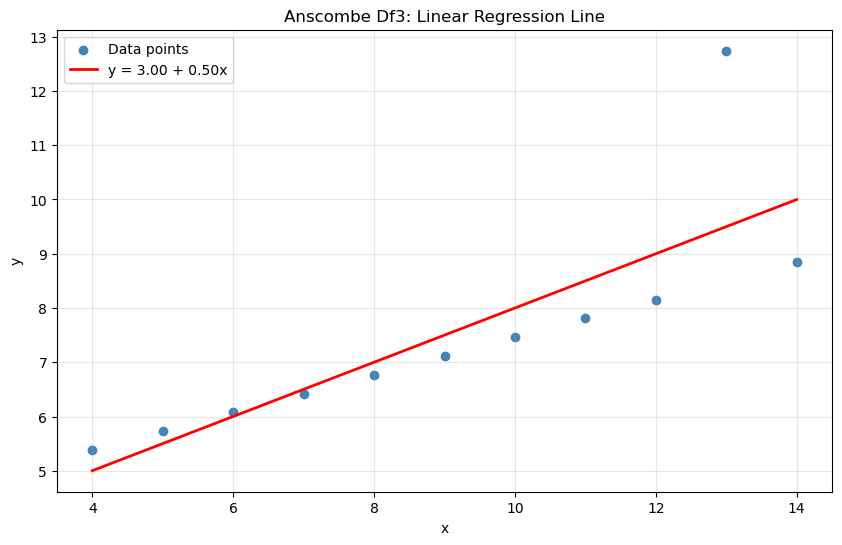

In [21]:
x_line = np.linspace(df3["x"].min(), df3["x"].max(), 100)
y_line = df3_slope[0] + df3_slope[1] * x_line

plt.figure(figsize=(10,6))
plt.scatter(df3["x"], df3["y"], color="steelblue", label="Data points")
plt.plot(x_line, y_line, color="red",
          linewidth=2, label=f"y = {df3_slope[0]:.2f} + {df3_slope[1]:.2f}x")
plt.xlabel("x")
plt.ylabel("y")
plt.title("Anscombe Df3: Linear Regression Line")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### 4. Analysis of Anscombe Dataset IV

In [22]:
df4 = df[df['dataset'] == "IV"]
df4

,dataset,x,y
33,IV,8.0,6.58
34,IV,8.0,5.76
35,IV,8.0,7.71
36,IV,8.0,8.84
37,IV,8.0,8.47
38,IV,8.0,7.04
39,IV,8.0,5.25
40,IV,19.0,12.50
41,IV,8.0,5.56
42,IV,8.0,7.91


In [23]:
df4_mean_x = compute_mean(df4['x'])
df4_mean_y = compute_mean(df4['y'])
print(f"Mean x: {df4_mean_x} | Mean y: {df4_mean_y}")

Mean x: 9.0 | Mean y: 7.500909090909091


In [24]:
df4_var_x = compute_sample_variance(df4['x'], df4_mean_x)
df4_var_y = compute_sample_variance(df4['y'], df4_mean_y)
print(f"Var x: {df4_var_x} | Var y: {df4_var_y}")

Var x: 11.0 | Var y: 4.123249090909091


In [25]:
df4_pearson_xy = compute_correlation(df4["x"],df4['y'],df4_mean_x,df4_mean_y)
print(f"Pearson r: {df4_pearson_xy}")

Pearson r: 0.816521436888503


In [26]:
df4_slope = compute_linear_regression(df4["x"],df4['y'],df4_mean_x,df4_mean_y)
print(f"Slope: {df4_slope}")

Slope: (3.0017272727272726, 0.49990909090909097)


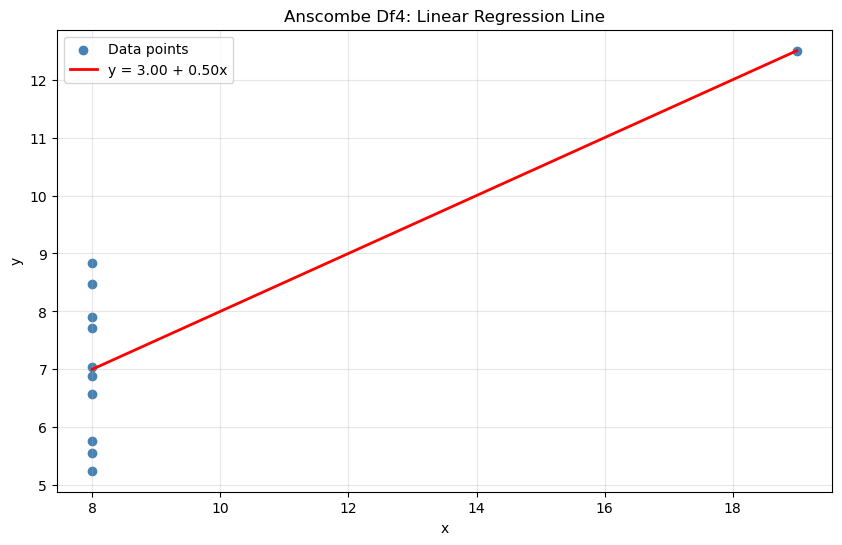

In [27]:
x_line = np.linspace(df4["x"].min(), df4["x"].max(), 100)
y_line = df4_slope[0] + df4_slope[1] * x_line

plt.figure(figsize=(10,6))
plt.scatter(df4["x"], df4["y"], color="steelblue", label="Data points")
plt.plot(x_line, y_line, color="red",
          linewidth=2, label=f"y = {df4_slope[0]:.2f} + {df4_slope[1]:.2f}x")
plt.xlabel("x")
plt.ylabel("y")
plt.title("Anscombe Df4: Linear Regression Line")
plt.legend()
plt.grid(alpha=0.3)
plt.savefig('anscombe.png', dpi=300, bbox_inches='tight', facecolor='white')
plt.show()

In [28]:
rows = []
for name, g in df.groupby("dataset"):
    mx, my = compute_mean(g["x"]), compute_mean(g["y"])
    b0, b1 = compute_linear_regression(g["x"], g["y"], mx, my)
    rows.append({
        "dataset": name,
        "mean_x": mx, "mean_y": my,
        "var_x": compute_sample_variance(g["x"], mx),
        "var_y": compute_sample_variance(g["y"], my),
        "pearson_r": compute_correlation(g["x"], g["y"], mx, my),
        "intercept": b0, "slope": b1,
    })

summary = pd.DataFrame(rows).round(2)
summary

,dataset,mean_x,mean_y,var_x,var_y,pearson_r,intercept,slope
0,I,9.0,7.5,11.0,4.13,0.82,3.0,0.5
1,II,9.0,7.5,11.0,4.13,0.82,3.0,0.5
2,III,9.0,7.5,11.0,4.12,0.82,3.0,0.5
3,IV,9.0,7.5,11.0,4.12,0.82,3.0,0.5


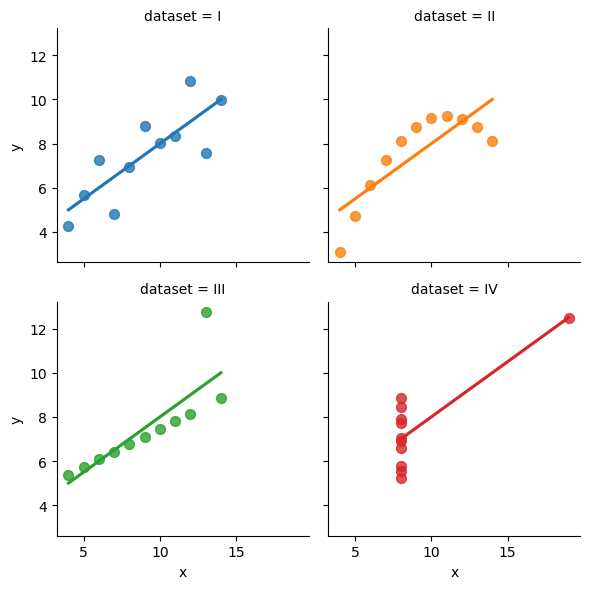

In [29]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

df = pd.read_csv('../Data/Cleaned_Data/anscombe_clean.csv')

sns.lmplot(x="x", y="y", col="dataset", hue="dataset", data=df,
           col_wrap=2, ci=None, height=3, scatter_kws={"s": 50})

plt.savefig('anscombe_grid.png', dpi=300, bbox_inches='tight', facecolor='white')
plt.show()